# Education Level vs Preferred Learning Method
## A researcher surveys 300 students to investigate whether education level is associated with their preferred learning method.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [3]:
education_level = np.array(["Matric","Intermediate","BS"])
online = np.array([50,35,20])
classroom = np.array([30,45,30])
hybrid = np.array([20,20,50])
observed_df = pd.DataFrame({
    "Education_level":education_level,
    "Online":online,
    "Classroom":classroom,
    "Hybrid":hybrid
    })
observed_df

,Education_level,Online,Classroom,Hybrid
0,Matric,50,30,20
1,Intermediate,35,45,20
2,BS,20,30,50


In [18]:
observed = observed_df[["Online","Classroom","Hybrid"]]
row_wise_sum = observed_df.sum(axis=1,numeric_only=True)
print("\n Row wise sum : \n",row_wise_sum)
column_wise = observed_df.sum(axis=0,numeric_only=True)
print("\nColumns wise sum : \n",column_wise)
total = observed.sum().sum()
print("\ntotal student : ",total)


 Row wise sum : 
 0    100
1    100
2    100
dtype: int64

Columns wise sum : 
 Online       105
Classroom    105
Hybrid        90
dtype: int64

total student :  300


In [21]:
expected  = np.outer(row_wise_sum,column_wise/total)
expected_df = pd.DataFrame(expected,index=education_level,columns=observed.columns)
expected_df

,Online,Classroom,Hybrid
Matric,35.0,35.0,30.0
Intermediate,35.0,35.0,30.0
BS,35.0,35.0,30.0


In [25]:
from scipy.stats import chi2_contingency
DOF = 4-1
chi_square_stats,p_value,DOF,expected_freq = chi2_contingency(observed)
print("chi square stats : ",chi_square_stats)
print("P value : ",p_value)
print("Degree of freedom : ",DOF)
print("expected frequency : \n",expected_freq)

chi square stats :  37.142857142857146
P value :  1.683269202388706e-07
Degree of freedom :  4
expected frequency : 
 [[35. 35. 30.]
 [35. 35. 30.]
 [35. 35. 30.]]


In [27]:
alpha = 0.05

if p_value < alpha:
    print("Decision: Reject the null hypothesis.")
    print("Conclusion: Education level is significantly associated with preferred learning method.")
else:
    print("Decision: Fail to reject the null hypothesis.")
    print("Conclusion: There is insufficient evidence of an association.")

Decision: Reject the null hypothesis.
Conclusion: Education level is significantly associated with preferred learning method.


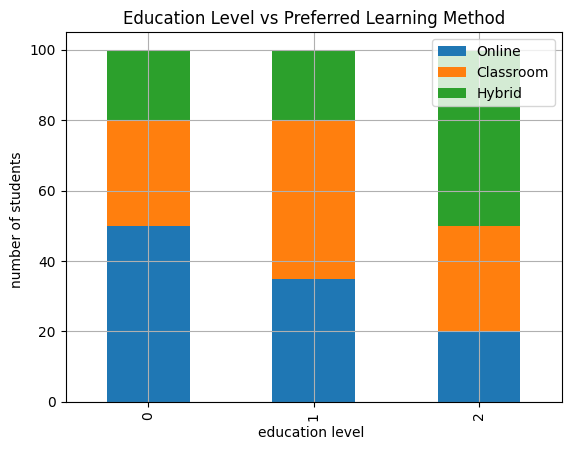

In [43]:
x = np.arange(len(observed))
plt.Figure(figsize=(9,9))
width = 0.40
observed.plot(kind="bar",stacked=True)
plt.title("Education Level vs Preferred Learning Method")
plt.xlabel("education level ")
plt.ylabel("number of students ")
plt.grid()
plt.show()